# Experiment No. 11

# Title
**A Neural Network Algorithm to Classify Data into Multiple Classes Based on Predictor Variables**

## Aim
To implement a neural network for multiclass classification using predictor variables.

## Objectives
1. Understand neural-network structure.
2. Train a model for multiple classes.
3. Evaluate predictions with classification metrics.

## Theory
A **Multilayer Perceptron (MLP)** is a feed-forward neural network. It learns weights and biases through backpropagation. A neuron computes \(z=\sum_i w_i x_i+b\); hidden layers commonly use ReLU, and multiclass output uses class probabilities.

# Step 1 - Import Libraries

Import the libraries for data processing, neural-network training, and evaluation.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# Step 2 - Load Dataset

Load Iris, a small dataset with three flower classes and four predictor variables.

In [34]:
iris = load_iris()
X = iris.data
y = iris.target
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", iris.target_names)

Feature shape: (150, 4)
Target shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


# Step 3 - Create DataFrame

Create a table with feature names and target labels.

In [35]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = y
df["class_name"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,class_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


# Step 4 - Dataset Information

Inspect the dataset columns and data types.

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   class_name         150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


# Step 5 - Summary Statistics

Display basic statistics for the predictor variables.

In [37]:
df[iris.feature_names].describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# Step 6 - Check Missing Values

Check for missing predictor values.

In [38]:
print(df[iris.feature_names].isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


# Step 7 - Class Distribution

Count samples belonging to each class.

In [39]:
print(df["class_name"].value_counts())

class_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


# Step 8 - Plot Class Distribution

Visualize the number of samples in each flower class.

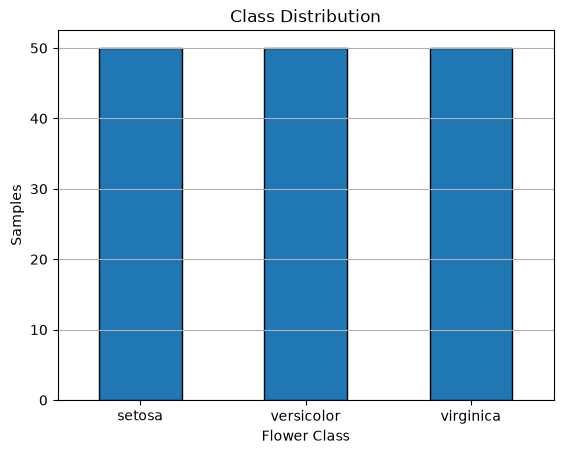

In [40]:
df["class_name"].value_counts().reindex(iris.target_names).plot(kind="bar", edgecolor="black")
plt.title("Class Distribution")
plt.xlabel("Flower Class")
plt.ylabel("Samples")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Step 9 - Visualize Predictor Variables

Plot petal length and width by class.

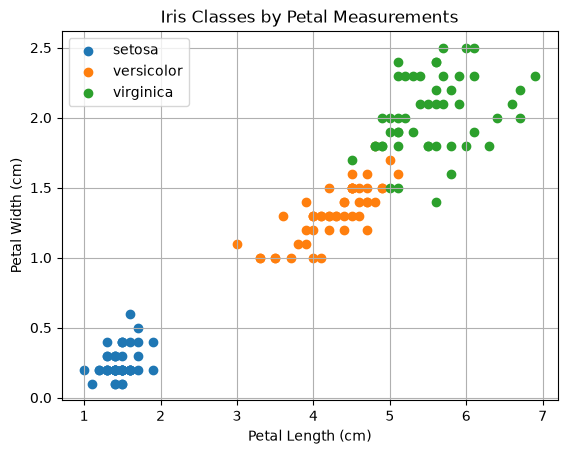

In [41]:
for i, name in enumerate(iris.target_names):
    d = df[df["target"] == i]
    plt.scatter(d["petal length (cm)"], d["petal width (cm)"], label=name)
plt.title("Iris Classes by Petal Measurements")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True)
plt.show()

# Step 10 - Separate Features and Target

Select predictor variables and class labels.

In [42]:
X = df[iris.feature_names].to_numpy()
y = df["target"].to_numpy()
print("X shape:", X.shape, "y shape:", y.shape)

X shape: (150, 4) y shape: (150,)


# Step 11 - Split Dataset

Create training and test sets while preserving class proportions.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


# Step 12 - Standardize Features

Fit the scaler only on training data, then transform both sets.

In [44]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled[:3])

[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]]


# Step 13 - Create Neural Network

Create an MLP with one hidden layer and three output classes.

In [45]:
mlp = MLPClassifier(
    hidden_layer_sizes=(10,), activation="relu", solver="adam",
    learning_rate_init=0.01, max_iter=1000, random_state=42
)
print(mlp)

MLPClassifier(hidden_layer_sizes=(10,), learning_rate_init=0.01, max_iter=1000,
              random_state=42)


# Step 14 - Train Neural Network

Fit the MLP model to the standardized training data.

In [46]:
mlp.fit(X_train_scaled, y_train)
print("Training completed.")

Training completed.


# Step 15 - Inspect Network Parameters

Display the shapes of learned weights and biases.

In [47]:
print("Layers:", mlp.n_layers_)
print("Output classes:", mlp.n_outputs_)
print("Weight shapes:", [w.shape for w in mlp.coefs_])
print("Bias shapes:", [b.shape for b in mlp.intercepts_])

Layers: 3
Output classes: 3
Weight shapes: [(4, 10), (10, 3)]
Bias shapes: [(10,), (3,)]


# Step 16 - Display Training Loss

Show the final training loss and number of iterations.

In [48]:
print("Final training loss:", round(mlp.loss_, 4))
print("Iterations:", mlp.n_iter_)

Final training loss: 0.0394
Iterations: 208


# Step 17 - Plot Training Loss

Plot the loss curve to see how training progressed.

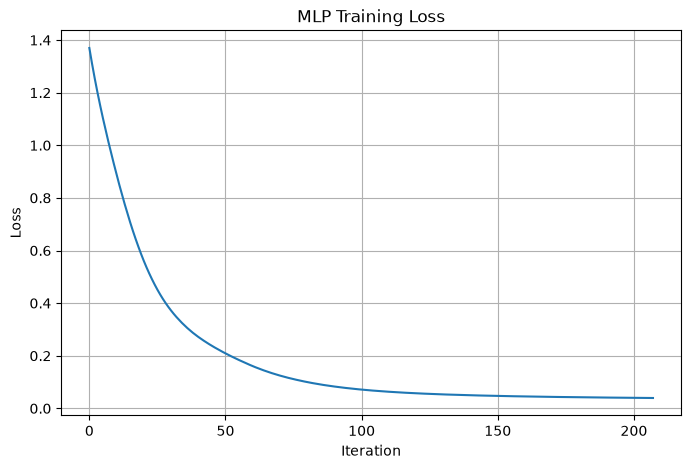

In [49]:
plt.figure(figsize=(8, 5))
plt.plot(mlp.loss_curve_)
plt.title("MLP Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Step 18 - Predict Training Classes

Predict labels for training examples.

In [50]:
y_train_pred = mlp.predict(X_train_scaled)
print("Actual:", y_train[:10])
print("Predicted:", y_train_pred[:10])

Actual: [0 2 1 0 1 2 1 2 2 2]
Predicted: [0 2 1 0 1 2 1 1 2 2]


# Step 19 - Calculate Training Accuracy

Measure the percentage of training predictions that are correct.

In [51]:
train_accuracy = accuracy_score(y_train, y_train_pred)
print("Training accuracy:", round(train_accuracy, 4))
print("Training accuracy (%):", round(train_accuracy * 100, 2))

Training accuracy: 0.9833
Training accuracy (%): 98.33


# Step 20 - Predict Test Classes

Predict labels for unseen test examples.

In [52]:
y_pred = mlp.predict(X_test_scaled)
print("Actual:", y_test[:15])
print("Predicted:", y_pred[:15])

Actual: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0]
Predicted: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0]


# Step 21 - Calculate Test Accuracy

Calculate overall classification accuracy on test data.

In [53]:
test_accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", round(test_accuracy, 4))
print("Test accuracy (%):", round(test_accuracy * 100, 2))

Test accuracy: 0.9667
Test accuracy (%): 96.67


# Step 22 - Calculate Precision

Calculate macro precision so each class receives equal weight.

In [54]:
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
print("Macro precision:", round(precision, 4))

Macro precision: 0.9697


# Step 23 - Calculate Recall

Calculate macro recall across the three classes.

In [55]:
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
print("Macro recall:", round(recall, 4))

Macro recall: 0.9667


# Step 24 - Calculate F1-Score

Calculate the macro F1-score, which combines precision and recall.

In [56]:
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
print("Macro F1-score:", round(f1, 4))

Macro F1-score: 0.9666


# Step 25 - Classification Report

Display precision, recall, F1-score, and support for each class.

In [57]:
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# Step 26 - Confusion Matrix

Compare actual and predicted classes in a confusion matrix.

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


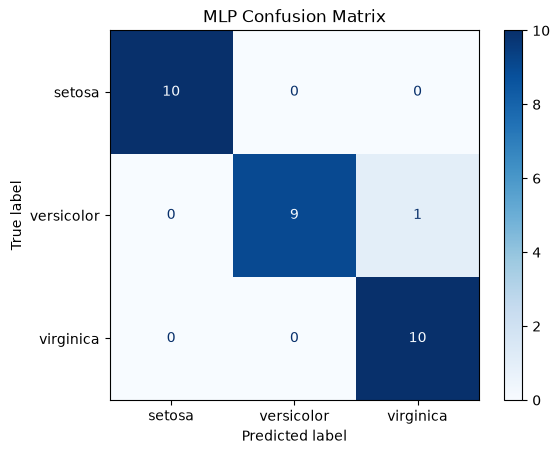

In [58]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("MLP Confusion Matrix")
plt.show()

# Step 27 - View Class Probabilities

Display predicted class probabilities for a few test samples.

In [59]:
probabilities = mlp.predict_proba(X_test_scaled)
display(pd.DataFrame(probabilities[:10], columns=iris.target_names).round(3))

,setosa,versicolor,virginica
0,1.000,0.000,0.000
1,0.001,0.176,0.823
2,0.014,0.986,0.000
3,0.005,0.995,0.000
4,1.000,0.000,0.000
5,0.005,0.917,0.079
6,1.000,0.000,0.000
7,0.997,0.003,0.000
8,0.000,0.005,0.995
9,0.009,0.938,0.053


# Step 28 - Compare Actual and Predicted

Create a table to inspect test predictions.

In [60]:
comparison = pd.DataFrame({
    "Actual Class": [iris.target_names[i] for i in y_test],
    "Predicted Class": [iris.target_names[i] for i in y_pred]
})
display(comparison.head(10))

,Actual Class,Predicted Class
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


# Step 29 - Predict a New Sample

Scale a new flower sample and predict its class.

In [61]:
# Step 29 - Predict a New Sample

new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])

new_scaled = scaler.transform(new_sample)

new_pred = mlp.predict(new_scaled)
new_probs = mlp.predict_proba(new_scaled)

print("New Sample:", new_sample)
print("Predicted class:", iris.target_names[new_pred[0]])

print("Class Probabilities:")
display(pd.DataFrame(
    new_probs,
    columns=iris.target_names
).round(4))

New Sample: [[5.1 3.5 1.4 0.2]]
Predicted class: setosa
Class Probabilities:


,setosa,versicolor,virginica
0,0.9996,0.0004,0.0


# Step 30 - Summarize Evaluation

Display the main test metrics in one table.

In [62]:
summary = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-Score"],
    "Score": [test_accuracy, precision, recall, f1]
})
display(summary.round(4))

,Metric,Score
0,Accuracy,0.9667
1,Macro Precision,0.9697
2,Macro Recall,0.9667
3,Macro F1-Score,0.9666


## Result and Conclusion

A Multilayer Perceptron was trained to classify Iris flowers into three classes using predictor variables. Performance was assessed with accuracy, macro precision, macro recall, macro F1-score, and a confusion matrix. The displayed metrics are the results calculated when the notebook is run.

